In [30]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/interim/blob_index/blob_index.csv")
video_df = pd.read_csv("../data/interim/blob_index/video_index.csv")

print("All blobs:", len(df))
print("Videos:", len(video_df))

All blobs: 252251
Videos: 252189


In [31]:
df.head()

,blob_name,size_bytes,suffix,top_level_dir,parent_dir,filename,is_video,last_modified,etag,location_from_name,camera_from_name,stream,start_time,end_time,duration_seconds
0,Haarle,0,NaN,NaN,NaN,Haarle,False,2025-03-31 11:35:36+00:00,0x8DD704827C67E88,NaN,NaN,NaN,NaN,NaN,NaN
1,Haarle/ch1,0,NaN,Haarle,Haarle,ch1,False,2025-03-31 11:36:13+00:00,0x8DD70483DEB2890,NaN,NaN,NaN,NaN,NaN,NaN
2,Haarle/ch1/Haarle_ch1_main_20250331050713_2025...,13499630,.mp4,Haarle,Haarle/ch1,Haarle_ch1_main_20250331050713_20250331050757.mp4,True,2025-04-11 10:57:51+00:00,0x8DD78E7B4461D4C,Haarle,ch1,main,2025-03-31T05:07:13,2025-03-31T05:07:57,44.0
3,Haarle/ch1/Haarle_ch1_main_20250331061711_2025...,12665545,.mp4,Haarle,Haarle/ch1,Haarle_ch1_main_20250331061711_20250331061754.mp4,True,2025-04-11 10:57:51+00:00,0x8DD78E7B46D74A4,Haarle,ch1,main,2025-03-31T06:17:11,2025-03-31T06:17:54,43.0
4,Haarle/ch1/Haarle_ch1_main_20250331064926_2025...,40933995,.mp4,Haarle,Haarle/ch1,Haarle_ch1_main_20250331064926_20250331065154.mp4,True,2025-04-11 10:57:54+00:00,0x8DD78E7B60047B0,Haarle,ch1,main,2025-03-31T06:49:26,2025-03-31T06:51:54,148.0


In [32]:
video_df.head()

,blob_name,size_bytes,suffix,top_level_dir,parent_dir,filename,is_video,last_modified,etag,location_from_name,camera_from_name,stream,start_time,end_time,duration_seconds
0,Haarle/ch1/Haarle_ch1_main_20250331050713_2025...,13499630,.mp4,Haarle,Haarle/ch1,Haarle_ch1_main_20250331050713_20250331050757.mp4,True,2025-04-11 10:57:51+00:00,0x8DD78E7B4461D4C,Haarle,ch1,main,2025-03-31T05:07:13,2025-03-31T05:07:57,44.0
1,Haarle/ch1/Haarle_ch1_main_20250331061711_2025...,12665545,.mp4,Haarle,Haarle/ch1,Haarle_ch1_main_20250331061711_20250331061754.mp4,True,2025-04-11 10:57:51+00:00,0x8DD78E7B46D74A4,Haarle,ch1,main,2025-03-31T06:17:11,2025-03-31T06:17:54,43.0
2,Haarle/ch1/Haarle_ch1_main_20250331064926_2025...,40933995,.mp4,Haarle,Haarle/ch1,Haarle_ch1_main_20250331064926_20250331065154.mp4,True,2025-04-11 10:57:54+00:00,0x8DD78E7B60047B0,Haarle,ch1,main,2025-03-31T06:49:26,2025-03-31T06:51:54,148.0
3,Haarle/ch1/Haarle_ch1_main_20250331065742_2025...,23413229,.mp4,Haarle,Haarle/ch1,Haarle_ch1_main_20250331065742_20250331065905.mp4,True,2025-04-11 10:57:53+00:00,0x8DD78E7B57CB204,Haarle,ch1,main,2025-03-31T06:57:42,2025-03-31T06:59:05,83.0
4,Haarle/ch1/Haarle_ch1_main_20250331071515_2025...,18714542,.mp4,Haarle,Haarle/ch1,Haarle_ch1_main_20250331071515_20250331071621.mp4,True,2025-04-11 10:57:55+00:00,0x8DD78E7B672A01C,Haarle,ch1,main,2025-03-31T07:15:15,2025-03-31T07:16:21,66.0


In [33]:
video_df.columns

Index(['blob_name', 'size_bytes', 'suffix', 'top_level_dir', 'parent_dir',
       'filename', 'is_video', 'last_modified', 'etag', 'location_from_name',
       'camera_from_name', 'stream', 'start_time', 'end_time',
       'duration_seconds'],
      dtype='str')

In [34]:
df["suffix"].value_counts().head(15)

suffix
.mp4    252189
.dav        37
Name: count, dtype: int64

In [35]:
video_df["top_level_dir"].value_counts()

top_level_dir
Meddo        62109
Randwijk     59423
Haarle       58714
Twisk        53204
Vosseveld    18739
Name: count, dtype: int64

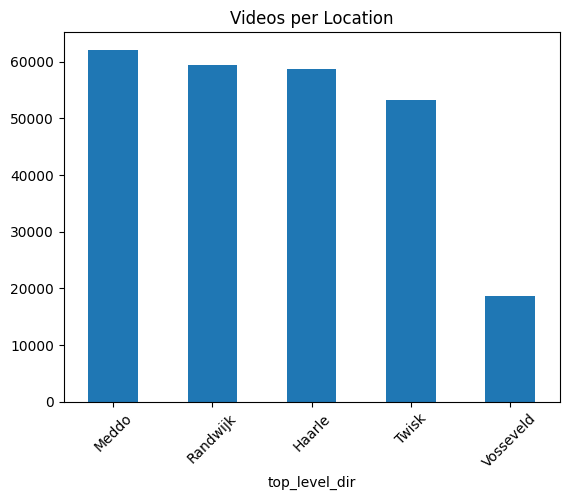

In [36]:
video_df["top_level_dir"].value_counts().head(10).plot(kind="bar")
plt.title("Videos per Location")
plt.xticks(rotation=45)
plt.show()

In [37]:
video_df["camera_from_name"].value_counts()

camera_from_name
ch3    100971
ch4     53693
ch1     53407
ch2     44118
Name: count, dtype: int64

In [38]:
video_df.groupby(["location_from_name", "camera_from_name"]).size().sort_values(ascending=False)

location_from_name  camera_from_name
Meddo               ch3                 26885
Haarle              ch3                 23785
Randwijk            ch3                 23187
Twisk               ch3                 22396
Meddo               ch1                 20796
Randwijk            ch2                 13593
Haarle              ch4                 12216
Twisk               ch4                 12011
Haarle              ch2                 11817
Randwijk            ch4                 11800
Haarle              ch1                 10896
Randwijk            ch1                 10843
Twisk               ch2                 10205
Meddo               ch4                  9364
Twisk               ch1                  8592
Vosseveld           ch4                  8302
Meddo               ch2                  5064
Vosseveld           ch3                  4718
                    ch2                  3439
                    ch1                  2280
dtype: int64

In [39]:
total_size_gb = video_df["size_bytes"].sum() / (1024**3)
print(f"Total video size: {total_size_gb:.2f} GB")

Total video size: 2703.07 GB


In [40]:
(video_df["size_bytes"] / (1024**2)).describe()

count    252189.000000
mean         10.975686
std          28.248017
min           0.000000
25%           0.791622
50%           4.224357
75%          10.950476
max        1779.300467
Name: size_bytes, dtype: float64

In [41]:
video_df["duration_seconds"].describe()

count    252189.000000
mean        100.482349
std         215.373576
min           0.000000
25%          37.000000
50%          43.000000
75%          80.000000
max        5381.000000
Name: duration_seconds, dtype: float64

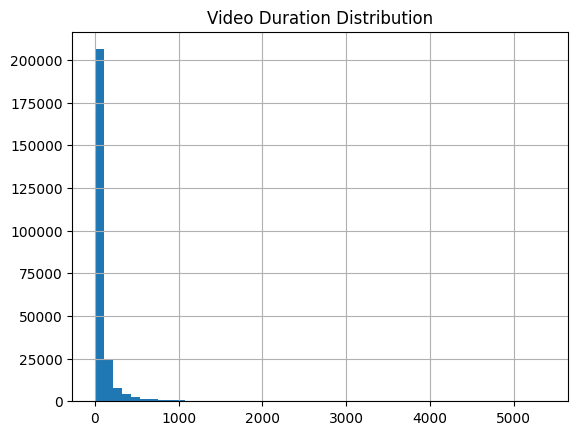

In [42]:
video_df["duration_seconds"].hist(bins=50)
plt.title("Video Duration Distribution")
plt.show()

In [43]:
video_df[video_df["duration_seconds"] < 5].head()

,blob_name,size_bytes,suffix,top_level_dir,parent_dir,filename,is_video,last_modified,etag,location_from_name,camera_from_name,stream,start_time,end_time,duration_seconds
20129,Haarle/ch2/Haarle_ch2_main_20250613050851_2025...,109207,.mp4,Haarle,Haarle/ch2,Haarle_ch2_main_20250613050851_20250613050855.mp4,True,2025-06-13 03:11:53+00:00,0x8DDAA280BD6C064,Haarle,ch2,main,2025-06-13T05:08:51,2025-06-13T05:08:55,4.0
24510,Haarle/ch3/Haarle_ch3_main_20250411000000_2025...,379644,.mp4,Haarle,Haarle/ch3,Haarle_ch3_main_20250411000000_20250411000001.mp4,True,2025-04-10 22:02:15+00:00,0x8DD787B5A7F9758,Haarle,ch3,main,2025-04-11T00:00:00,2025-04-11T00:00:01,1.0
26711,Haarle/ch3/Haarle_ch3_main_20250418000000_2025...,1188928,.mp4,Haarle,Haarle/ch3,Haarle_ch3_main_20250418000000_20250418000004.mp4,True,2025-04-17 22:02:17+00:00,0x8DD7DFB849EC3A4,Haarle,ch3,main,2025-04-18T00:00:00,2025-04-18T00:00:04,4.0
36820,Haarle/ch3/Haarle_ch3_main_20250525080001_2025...,411102,.mp4,Haarle,Haarle/ch3,Haarle_ch3_main_20250525080001_20250525080005.mp4,True,2025-05-25 06:04:36+00:00,0x8DD9B5206F104C4,Haarle,ch3,main,2025-05-25T08:00:01,2025-05-25T08:00:05,4.0
39402,Haarle/ch3/Haarle_ch3_main_20250605000000_2025...,22856,.mp4,Haarle,Haarle/ch3,Haarle_ch3_main_20250605000000_20250605000000.mp4,True,2025-06-04 22:02:36+00:00,0x8DDA3B384238678,Haarle,ch3,main,2025-06-05T00:00:00,2025-06-05T00:00:00,0.0


In [44]:
video_df["start_time"] = pd.to_datetime(video_df["start_time"])

video_df["hour"] = video_df["start_time"].dt.hour
video_df["hour"].value_counts().sort_index()

hour
0     10684
1      9936
2      9661
3      9985
4     10947
5     10828
6     10924
7     10822
8     11091
9     11259
10    10683
11    10066
12    10339
13    10593
14     9748
15     9218
16     9454
17     9666
18     9789
19     9376
20    10621
21    10943
22    13286
23    12270
Name: count, dtype: int64

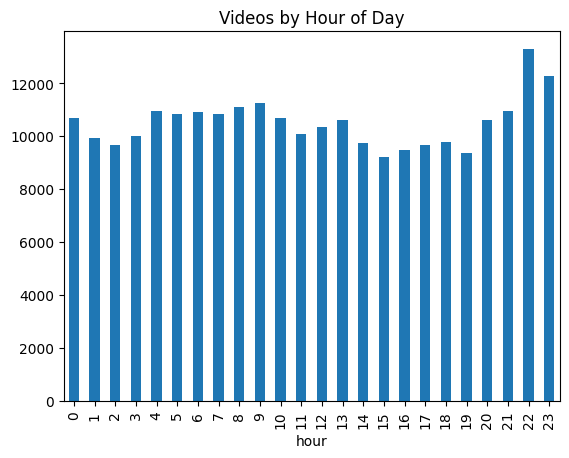

In [45]:
video_df["hour"].value_counts().sort_index().plot(kind="bar")
plt.title("Videos by Hour of Day")
plt.show()

In [47]:
video_df["date"] = video_df["start_time"].dt.date
video_df["date"].value_counts().head()

date
2025-06-10    4927
2025-06-09    4606
2025-06-12    4505
2025-05-30    4214
2025-05-26    4208
Name: count, dtype: int64

In [48]:
video_df.sort_values("size_bytes", ascending=False).head(10)

,blob_name,size_bytes,suffix,top_level_dir,parent_dir,filename,is_video,last_modified,etag,location_from_name,camera_from_name,stream,start_time,end_time,duration_seconds,hour,date
113494,Meddo/ch4/Meddo_ch4_main_20250501145706_202505...,1865731766,.mp4,Meddo,Meddo/ch4,Meddo_ch4_main_20250501145706_20250501154412.mp4,True,2025-05-01 14:04:42+00:00,0x8DD88B91EBB8430,Meddo,ch4,main,2025-05-01 14:57:06,2025-05-01T15:44:12,2826.0,14,2025-05-01
59985,Meddo/ch1/Meddo_ch1_main_20250406103904_202504...,1193832053,.mp4,Meddo,Meddo/ch1,Meddo_ch1_main_20250406103904_20250406115256.mp4,True,2025-04-11 12:01:20+00:00,0x8DD78F092FCA6C4,Meddo,ch1,main,2025-04-06 10:39:04,2025-04-06T11:52:56,4432.0,10,2025-04-06
60204,Meddo/ch1/Meddo_ch1_main_20250407125845_202504...,991957990,.mp4,Meddo,Meddo/ch1,Meddo_ch1_main_20250407125845_20250407140000.mp4,True,2025-04-11 12:09:16+00:00,0x8DD78F1AE64F974,Meddo,ch1,main,2025-04-07 12:58:45,2025-04-07T14:00:00,3675.0,12,2025-04-07
117551,Meddo/ch4/Meddo_ch4_main_20250610183700_202506...,985584275,.mp4,Meddo,Meddo/ch4,Meddo_ch4_main_20250610183700_20250610200000.mp4,True,2025-06-10 18:26:13+00:00,0x8DDA84C4833EF70,Meddo,ch4,main,2025-06-10 18:37:00,2025-06-10T20:00:00,4980.0,18,2025-06-10
60206,Meddo/ch1/Meddo_ch1_main_20250407150000_202504...,970461367,.mp4,Meddo,Meddo/ch1,Meddo_ch1_main_20250407150000_20250407160000.mp4,True,2025-04-11 12:10:15+00:00,0x8DD78F1D1892608,Meddo,ch1,main,2025-04-07 15:00:00,2025-04-07T16:00:00,3600.0,15,2025-04-07
60205,Meddo/ch1/Meddo_ch1_main_20250407140000_202504...,970289190,.mp4,Meddo,Meddo/ch1,Meddo_ch1_main_20250407140000_20250407150000.mp4,True,2025-04-11 12:09:13+00:00,0x8DD78F1ACC299E4,Meddo,ch1,main,2025-04-07 14:00:00,2025-04-07T15:00:00,3600.0,14,2025-04-07
87377,Meddo/ch3/Meddo_ch3_main_20250415083509_202504...,933698227,.mp4,Meddo,Meddo/ch3,Meddo_ch3_main_20250415083509_20250415093336.mp4,True,2025-04-15 07:47:08+00:00,0x8DD7BF1B95219AC,Meddo,ch3,main,2025-04-15 08:35:09,2025-04-15T09:33:36,3507.0,8,2025-04-15
60202,Meddo/ch1/Meddo_ch1_main_20250407114153_202504...,885515047,.mp4,Meddo,Meddo/ch1,Meddo_ch1_main_20250407114153_20250407123644.mp4,True,2025-04-11 12:08:13+00:00,0x8DD78F188B98720,Meddo,ch1,main,2025-04-07 11:41:53,2025-04-07T12:36:44,3291.0,11,2025-04-07
169696,Randwijk/ch4/Randwijk_ch4_main_20250415095350_...,860929947,.mp4,Randwijk,Randwijk/ch4,Randwijk_ch4_main_20250415095350_2025041510482...,True,2025-04-15 09:14:43+00:00,0x8DD7BFDF5DE49A8,Randwijk,ch4,main,2025-04-15 09:53:50,2025-04-15T10:48:22,3272.0,9,2025-04-15
91376,Meddo/ch3/Meddo_ch3_main_20250426173233_202504...,838151090,.mp4,Meddo,Meddo/ch3,Meddo_ch3_main_20250426173233_20250426182453.mp4,True,2025-04-26 16:37:48+00:00,0x8DD84E0ADE9F238,Meddo,ch3,main,2025-04-26 17:32:33,2025-04-26T18:24:53,3140.0,17,2025-04-26


In [49]:
video_df[video_df["location_from_name"].isna()].head()

,blob_name,size_bytes,suffix,top_level_dir,parent_dir,filename,is_video,last_modified,etag,location_from_name,camera_from_name,stream,start_time,end_time,duration_seconds,hour,date


In [50]:
video_df.groupby("location_from_name")["duration_seconds"].mean()

location_from_name
Haarle       113.149266
Meddo        100.621617
Randwijk      98.689295
Twisk        101.841478
Vosseveld     62.159187
Name: duration_seconds, dtype: float64

In [51]:
video_df.groupby(["location_from_name", "camera_from_name"]).size().reset_index(name="count")

,location_from_name,camera_from_name,count
0,Haarle,ch1,10896
1,Haarle,ch2,11817
2,Haarle,ch3,23785
3,Haarle,ch4,12216
4,Meddo,ch1,20796
5,Meddo,ch2,5064
6,Meddo,ch3,26885
7,Meddo,ch4,9364
8,Randwijk,ch1,10843
9,Randwijk,ch2,13593


In [55]:
video_df["start_time"] = pd.to_datetime(video_df["start_time"])
video_df["date"] = video_df["start_time"].dt.date

videos_per_day = video_df["date"].value_counts().sort_index()
videos_per_day

date
2025-03-27       1
2025-03-31      69
2025-04-01     388
2025-04-02    2128
2025-04-03    2150
              ... 
2025-06-28    1363
2025-06-29     917
2025-06-30    1054
2025-07-01     905
2025-07-02     271
Name: count, Length: 95, dtype: int64

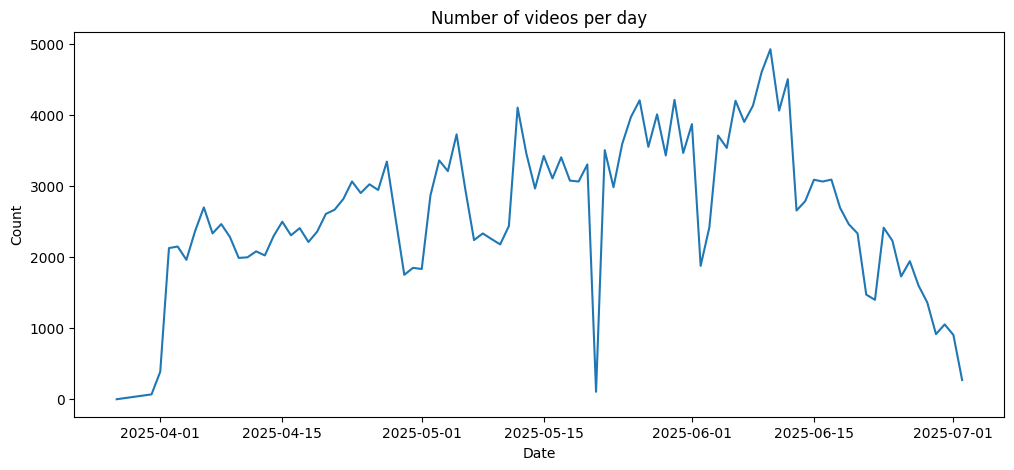

In [56]:
videos_per_day.plot(figsize=(12,5))
plt.title("Number of videos per day")
plt.xlabel("Date")
plt.ylabel("Count")
plt.show()

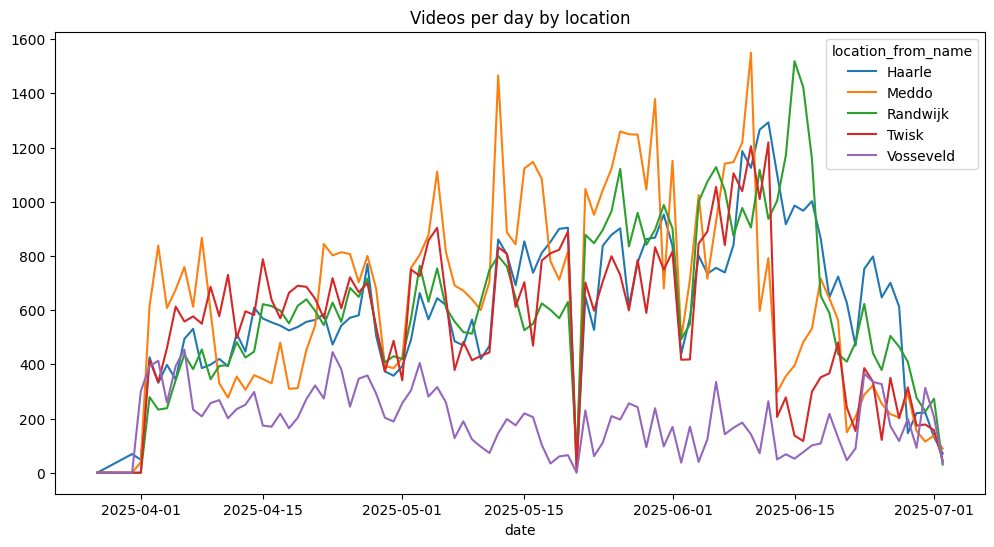

In [58]:
video_df.groupby(["date", "location_from_name"]).size().unstack().fillna(0).plot(figsize=(12,6))
plt.title("Videos per day by location")
plt.show()

In [54]:
loc_counts = video_df["location_from_name"].fillna("UNKNOWN").value_counts()
cam_counts = video_df["camera_from_name"].fillna("UNKNOWN").value_counts()

duration = video_df["duration_seconds"].dropna()
short_threshold = 5
very_short_count = (duration < short_threshold).sum()
very_short_pct = very_short_count / len(duration) * 100

video_df["start_time"] = pd.to_datetime(video_df["start_time"], errors="coerce")
video_df["hour_tmp"] = video_df["start_time"].dt.hour
hour_counts = video_df["hour_tmp"].value_counts().sort_index()

print("=== Locations ===")
print(f"Unique locations: {loc_counts.shape[0]}")
print("Top 5 locations:")
print(loc_counts.head(5).to_string())
print("Min per location:", int(loc_counts.min()), "Max per location:", int(loc_counts.max()))
print("Max/min ratio:", round(float(loc_counts.max() / max(loc_counts.min(), 1)), 2))

print("\n=== Cameras ===")
print(f"Unique cameras: {cam_counts.shape[0]}")
print("Lowest-count cameras (up to 10):")
print(cam_counts.sort_values().head(10).to_string())

print("\n=== Video duration (seconds) ===")
print(duration.describe().to_string())
print(f"Coefficient of variation (std/mean): {float(duration.std() / duration.mean()):.2f}")
print(f"Very short videos (<{short_threshold} sec): {very_short_count} ({very_short_pct:.2f}%)")

print("\n=== Time of day (by hour) ===")
print(hour_counts.to_string())
print("Min per hour:", int(hour_counts.min()), "Max per hour:", int(hour_counts.max()))
print("Max/min hourly ratio:", round(float(hour_counts.max() / max(hour_counts.min(), 1)), 2))

=== Locations ===
Unique locations: 5
Top 5 locations:
location_from_name
Meddo        62109
Randwijk     59423
Haarle       58714
Twisk        53204
Vosseveld    18739
Min per location: 18739 Max per location: 62109
Max/min ratio: 3.31

=== Cameras ===
Unique cameras: 4
Lowest-count cameras (up to 10):
camera_from_name
ch2     44118
ch1     53407
ch4     53693
ch3    100971

=== Video duration (seconds) ===
count    252189.000000
mean        100.482349
std         215.373576
min           0.000000
25%          37.000000
50%          43.000000
75%          80.000000
max        5381.000000
Coefficient of variation (std/mean): 2.14
Very short videos (<5 sec): 36 (0.01%)

=== Time of day (by hour) ===
hour_tmp
0     10684
1      9936
2      9661
3      9985
4     10947
5     10828
6     10924
7     10822
8     11091
9     11259
10    10683
11    10066
12    10339
13    10593
14     9748
15     9218
16     9454
17     9666
18     9789
19     9376
20    10621
21    10943
22    13286
23    1

## Conclusions

### 1. Location imbalance

There is a **moderate imbalance across locations**.  
The number of videos per location ranges from **18,739 (Vosseveld)** to **62,109 (Meddo)**, resulting in a **3.31× difference**.

This indicates that:
- some locations are significantly overrepresented;
- sampling must account for this imbalance to avoid bias in the model.

---

### 2. Camera distribution

There is also a **noticeable imbalance across cameras**.  

For example:
- `ch2`: **44,118 videos**
- `ch3`: **100,971 videos**

Although all cameras are well represented, the distribution is uneven and may introduce bias if not handled properly.

---

### 3. Video duration

Video durations are **highly variable**:
- mean: **100.5 seconds**
- standard deviation: **215.4 seconds**
- coefficient of variation: **2.14**
- maximum: **5,381 seconds**

This indicates a **heavy-tailed distribution**, meaning:
- most videos are relatively short;
- but there are significant outliers with very long durations.

This variability should be considered during:
- frame extraction;
- normalization;
- dataset balancing.

---

### 4. Data noise (very short videos)

Very short videos (<5 seconds) are **rare**:
- **36 videos total**
- only **0.01% of the dataset**

Conclusion:
- noise is minimal;
- removing these samples will not significantly affect dataset size.

---

### 5. Time-of-day distribution

The distribution across hours shows a **mild imbalance**:
- minimum: **9,218 videos/hour**
- maximum: **13,286 videos/hour**
- ratio: **1.44×**

There is slightly higher activity in the **late evening (22:00–23:00)**.

Conclusion:
- no severe temporal bias;
- but mild skew should still be considered during sampling.

---

## Overall conclusion

The dataset is generally well-structured but exhibits:
- moderate imbalance across locations and cameras;
- strong variability in video duration;
- slight temporal skew.

Therefore, **random sampling is not appropriate**.

A **balanced sampling strategy** should be used, taking into account:
- location;
- camera;
- time (hour or day).